**Prénom :** Hamadou

**Nom :** BA

M2 IWOCS, Apprentissage automatique, restitution du TP 3

# TP 3 "Régression polynomiale / Régularisation"

*M2 IWOCS, Apprentissage automatique*

## Données du problème
Télécharger l’archive correspondant aux données de l’exercice 3/TP 3, décompactez-la. cette archive contient deux fichiers, un pour les données d'entrée $x$ qui sont ici à une dimension, et l’autre pour les données de sorties y à une dimension également. Tracer un graphique représentant le nuage de points défini par ces données dans le style du celui qui est représenté dans la figure suivante.
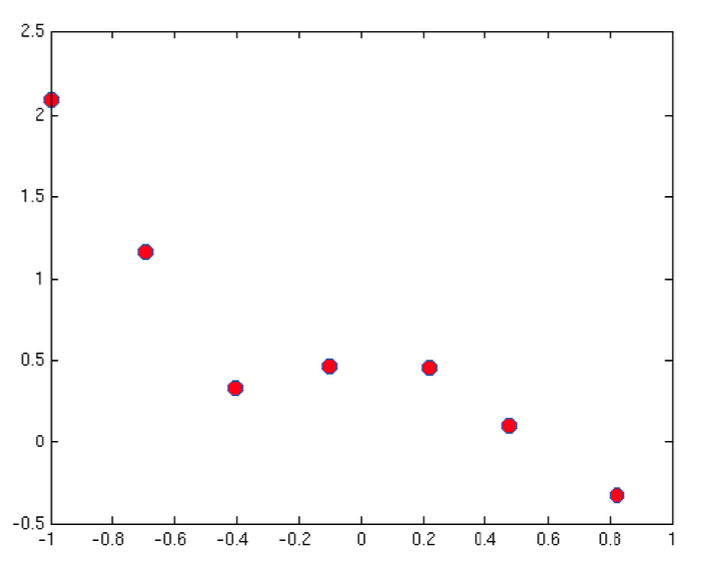

### Réponse : Lecture et représentation des données

Les deux fichiers `ex3Linx.dat` et `ex3Liny.dat` (placés dans le dossier `data/`) sont lus avec `np.loadtxt`. Comme dans le cours, les vecteurs 1D de format `(m,)` sont transformés en matrices colonnes de format `(m,1)` avec `np.newaxis`, afin de pouvoir écrire tous les calculs sous forme matricielle.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["font.size"] = 12

# lecture des données
x = np.loadtxt("data/ex3Linx.dat")
y = np.loadtxt("data/ex3Liny.dat")

# transformation des vecteurs 1D en matrices à 1 colonne
x = x[:, np.newaxis]
y = y[:, np.newaxis]
m = len(y)  # nombre de données

print("x.shape :", x.shape, " y.shape :", y.shape, " m =", m)
print("x =", x.ravel())
print("y =", y.ravel())

x.shape : (7, 1)  y.shape : (7, 1)  m = 7
x = [-0.9977 -0.6957 -0.4037 -0.1024  0.2202  0.4774  0.8223]
y = [ 2.0885  1.1646  0.3287  0.4601  0.4481  0.1001 -0.3295]


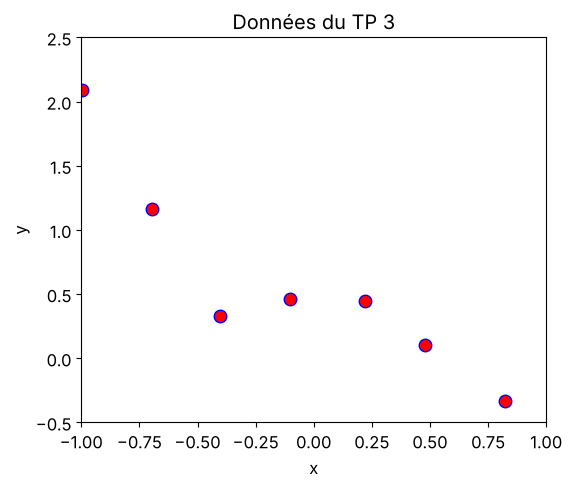

In [2]:
def trace_donnees(ax):
    """Nuage de points dans le style de la figure de l'énoncé."""
    ax.plot(x, y, "o", markersize=9, markerfacecolor="red",
            markeredgecolor="blue", label="Training data")
    ax.set_xlim(-1, 1)
    ax.set_ylim(-0.5, 2.5)
    ax.set_xlabel("x")
    ax.set_ylabel("y")

fig, ax = plt.subplots(figsize=(6, 5))
trace_donnees(ax)
ax.set_title("Données du TP 3")
plt.show()

On retrouve le nuage de 7 points de la figure de l'énoncé. Les données ne sont clairement pas alignées : une régression linéaire simple (droite) ne suffirait pas, d'où le recours à une hypothèse polynomiale.

## Analyse du problème
On propose de modéliser ces données par une fonction hypothèse polynomiale de degré 5 :

$$
h_{\theta}(x) = \theta_0 + \theta_1 x + \theta_2 x^2 + + \theta_3 x^3 + \theta_4 x^4 + \theta_5 x^5
$$

Comme expliqué dans le cours, cela revient à considérer 6 descripteurs constituant les différentes puissances de $x$ dans le polynôme. Le problème reste cependant linéaire par rapport à ces descripteurs.

Le degré du polynôme étant 5 et le nombre de points initiaux 7, le risque de sur-apprentissage (over-fitting) est grand. Il est donc nécessaire de *régulariser* le modèle.

Pour cela on va corriger le calcul de la fonction de coût en utilisant une variante de la régularisation de Ridge vu en cours et qui s'écrit :

$$
J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}\left(h_\theta(x_i)-y_i\right)^2+\lambda \sum_{j=1}^{n}\theta_j^2
$$

Le paramètre de régularisation $\lambda$ va permettre d’éviter des valeurs importantes de $\theta$ qui feraient augmenter la valeur de la fonction de coût. A noter que la composantes $\theta_0$ n’intervient pas dans la sommation devant $\lambda$.


### Réponse : Construction de la matrice des descripteurs

Comme dans le cours (où `PolynomialFeatures` construit la ligne $(1, x_i, x_i^2, x_i^3)$), on transforme le problème polynomial univarié de degré 5 en un problème **linéaire multivarié** à $n = 5$ descripteurs $x, x^2, \dots, x^5$ (plus la colonne de 1 associée à $\theta_0$), soit 6 paramètres $\theta_0,\dots,\theta_5$ à estimer à partir de seulement $m = 7$ points.

In [3]:
def matrice_poly(x, degre=5):
    """Matrice X = [1, x, x^2, ..., x^degre] (une ligne par donnée)."""
    xone = np.ones((len(x), 1))
    return np.block([[xone] + [x**k for k in range(1, degre + 1)]])

xone = np.ones((m, 1))
X = np.block([[xone, x, x**2, x**3, x**4, x**5]])   # construction de l'énoncé
assert np.allclose(X, matrice_poly(x))

print("X.shape :", X.shape)
print(X)
print("Conditionnement de X : %.1f" % np.linalg.cond(X))
print("Conditionnement de X^t X : %.0f" % np.linalg.cond(X.T @ X))

X.shape : (7, 6)
[[ 1.     -0.9977  0.9954 -0.9931  0.9908 -0.9885]
 [ 1.     -0.6957  0.4841 -0.3368  0.2343 -0.163 ]
 [ 1.     -0.4037  0.163  -0.0658  0.0266 -0.0107]
 [ 1.     -0.1024  0.0105 -0.0011  0.0001 -0.    ]
 [ 1.      0.2202  0.0485  0.0107  0.0024  0.0005]
 [ 1.      0.4774  0.2279  0.1088  0.052   0.0248]
 [ 1.      0.8223  0.6762  0.556   0.4572  0.3759]]
Conditionnement de X : 77.1
Conditionnement de X^t X : 5951


**Commentaire.** Avec 6 paramètres pour 7 équations, le modèle a presque assez de liberté pour passer exactement par tous les points (il faudrait 7 paramètres, soit un polynôme de degré 6, pour une interpolation exacte). Les colonnes $x^3$ et $x^5$ (ou $x^2$ et $x^4$) sont très corrélées sur $[-1,1]$, si bien que la matrice $X^tX$ intervenant dans la minimisation est mal conditionnée (conditionnement de l'ordre de $6\cdot10^3$). Cela traduit l'instabilité du problème : de petites variations des données peuvent entraîner de grandes variations des coefficients $\theta$. C'est exactement la situation de **sur-apprentissage** décrite dans le cours, d'où la nécessité de régulariser.

## Modification des formulations matricielles pour intégrer le terme de régularisation de type Ridge
L'introduction de la régularisation intervient dans la fonction de calcul du coût et dans le calcul de la minimisation de la fonction coût avec la méthode de gradient

### Calcul du coût

Formule du coût avec la régularisation proposée dans l'exercice (variante de la régularisation de Ridge) :
$$
J(\theta) = \frac{1}{2m}\sum_{i=1}^{m}\left(h_\theta(x_i)-y_i\right)^2+\lambda \sum_{j=1}^{n}\theta_j^2
$$

Comme vu précédemment, la première partie de cette formule (avant le terme de régularisation)
$$
\frac{1}{2m}\sum_{i=1}^{m}\left(h_\theta(x_i)-y_i\right)^2
$$
s'écrit en notation matricielle
$$
\frac{1}{2m}\left[h_\theta(X)-Y\right]^t \left[h_\theta(X)-Y\right]
$$
avec
\begin{align}
 \text{avec} \quad
 h_\theta(X) &= X \theta\\
             &= 
             \begin{bmatrix}
             1 & x_{11} & \cdots & x_{1n}\\
             \vdots & \vdots & & \vdots\\
             1 & x_{m1} & \cdots & x_{mn}\\
             \end{bmatrix}
             \begin{bmatrix}
             \theta_0\\
             \vdots\\
             \theta_n
             \end{bmatrix}\\
\text{et} \quad 
Y &= \begin{bmatrix}
      y_1\\
      \vdots\\
      y_m
      \end{bmatrix}
\end{align}

On doit alors ajouter à la fonction coût, le terme $\lambda \sum_{j=1}^{n}\theta_j^2$ (attention : on a exclu $\theta_0$). En notation matricielle, cette expression s'écrit

$$
\lambda [\theta_-]^t[\theta_-] \quad \text{où} \quad 
\theta_- = \begin{bmatrix}
                0\\
                \theta_1\\
                \vdots\\
                \theta_n
            \end{bmatrix}
$$
Donc au final $J(\theta)$ s'écrit en notation matricielle
$$
J(\theta) = \frac{1}{2m}\left[X \theta -Y \right]^t \left[X \theta - Y\right] + \lambda [\theta_-]^t[\theta_-]
$$

###  Calcul de la minimisation de la fonction de coût régularisée avec la méthode de gradiant

A chaque itération, on calcule une nouvelle valeur de $\theta^*$ à partir de $\theta$ telle que $J(\theta^*) < J(\theta)$.

La méthode de gradient correspond au calcul suivant :
$$
\theta^* = \theta - \alpha \nabla J(\theta)
$$

\begin{cases}
\theta_0^* &= \theta_0 - \alpha \displaystyle{\frac{\partial}{\partial \theta_0}} J(\theta)\\
\vdots\\
\theta_k^* &= \theta_k - \alpha \displaystyle{\frac{\partial}{\partial \theta_k}} J(\theta)\\
\vdots\\
\theta_k^* &= \theta_k - \alpha \displaystyle{\frac{\partial}{\partial \theta_k}} J(\theta)
\end{cases}

\begin{align}
\displaystyle{\frac{\partial}{\partial \theta_k}} J(\theta) &= 
    \displaystyle{\frac{\partial}{\partial \theta_k}} 
        \left( \frac{1}{2m}\sum_{i=1}^{m}\left(h_\theta(x_i)-y_i\right)^2+\lambda \sum_{j=1}^{n}\theta_j^2 \right)\\
     &= \frac{1}{m}\left(\sum_{i=1}^{m}\left(h_\theta(x_i)-y_i\right)x_{ik}\right) + 2 \lambda \theta_k
\end{align}
Le dernier terme du membre droit de l'équation $2 \lambda \theta_k$ vaut 0 si $k=0$ en raison de la formule de régularisation utilisée.

La formulation matricielle s'écrit ainsi (en utilisant que $h_\theta(X) = X \theta$) :
$$
\theta^* = \theta - \alpha \left[ \frac{1}{m} X^t [X \theta - Y] + 2 \lambda \theta_- \right]
$$

### Réponse : Implémentation matricielle du coût et du gradient régularisés

On traduit directement les formules matricielles précédentes :

- coût : $J(\theta) = \frac{1}{2m}[X\theta - Y]^t[X\theta - Y] + \lambda\,\theta_-^t\theta_-$ ;
- gradient : $\nabla J(\theta) = \frac{1}{m}X^t[X\theta - Y] + 2\lambda\,\theta_-$ ;
- itération : $\theta^* = \theta - \alpha\,\nabla J(\theta)$.

Le paramètre `ridge_complet` permettra de traiter aussi la régularisation de Ridge **complète** du cours (où $\theta_0$ est pénalisé) pour la discussion demandée plus loin : il suffit alors de remplacer $\theta_-$ par $\theta$.

**Choix du pas $\alpha$.** La fonction $J$ est quadratique ; sa matrice hessienne vaut $H = \frac{1}{m}X^tX + 2\lambda D$ avec $D = \mathrm{diag}(0,1,\dots,1)$. La méthode de gradient converge si $\alpha < 2/\lambda_{max}(H)$. On prend $\alpha = 1/\big(\lambda_{max}(\frac{1}{m}X^tX) + 2\lambda\big)$, ce qui garantit la convergence quelle que soit la valeur de $\lambda$ (un pas fixe comme $\alpha = 0.5$ diverge pour $\lambda = 10$).

**Critère d'arrêt.** On itère jusqu'à ce que la norme du gradient devienne inférieure à $10^{-10}$ (ou jusqu'à un nombre maximal d'itérations).

In [4]:
def theta_moins(theta):
    """Vecteur theta_- : copie de theta avec la composante theta_0 mise à 0."""
    t = theta.copy()
    t[0] = 0
    return t


def calcul_cout(X, Y, theta, lam, ridge_complet=False):
    """J(theta) = 1/(2m) [X theta - Y]^t [X theta - Y] + lambda theta_-^t theta_-"""
    m = len(Y)
    r = X @ theta - Y
    t = theta if ridge_complet else theta_moins(theta)
    return (r.T @ r / (2 * m) + lam * t.T @ t).item()


def calcul_gradient(X, Y, theta, lam, ridge_complet=False):
    """grad J(theta) = 1/m X^t [X theta - Y] + 2 lambda theta_-"""
    m = len(Y)
    t = theta if ridge_complet else theta_moins(theta)
    return X.T @ (X @ theta - Y) / m + 2 * lam * t


def descente_gradient(X, Y, lam, alpha=None, n_iter=500000, tol=1e-10, ridge_complet=False):
    """Minimisation de J par la méthode de gradient.
    Renvoie theta, l'historique des valeurs de J et le nombre d'itérations effectuées."""
    m, n = X.shape
    if alpha is None:
        alpha = 1 / (np.linalg.eigvalsh(X.T @ X / m).max() + 2 * lam)
    theta = np.zeros((n, 1))
    J_hist = [calcul_cout(X, Y, theta, lam, ridge_complet)]
    for it in range(1, n_iter + 1):
        g = calcul_gradient(X, Y, theta, lam, ridge_complet)
        theta = theta - alpha * g
        J_hist.append(calcul_cout(X, Y, theta, lam, ridge_complet))
        if np.linalg.norm(g) < tol:
            break
    return theta, np.array(J_hist), it


def predire(theta, x):
    """Valeurs de l'hypothèse h_theta aux points x."""
    return matrice_poly(x, len(theta) - 1) @ theta

**Vérification par l'équation normale.** Le minimum de $J$ annule le gradient :

$$
\frac{1}{m}X^t[X\theta - Y] + 2\lambda\,D\theta = 0
\quad\Longleftrightarrow\quad
\left(X^tX + 2m\lambda D\right)\theta = X^tY .
$$

Cette solution exacte (version régularisée de l'équation normale) sert uniquement à **contrôler** le résultat de la descente de gradient.

In [5]:
def equation_normale(X, Y, lam, ridge_complet=False):
    """Solution exacte de (X^t X + 2 m lambda D) theta = X^t Y."""
    m, n = X.shape
    D = np.eye(n)
    if not ridge_complet:
        D[0, 0] = 0
    return np.linalg.solve(X.T @ X + 2 * m * lam * D, X.T @ Y)


# test rapide du gradient par différences finies (lambda = 1, theta quelconque)
rng = np.random.default_rng(0)
theta_test = rng.normal(size=(6, 1))
eps = 1e-6
g_num = np.array([[(calcul_cout(X, y, theta_test + eps * e, 1) - calcul_cout(X, y, theta_test - eps * e, 1)) / (2 * eps)]
                  for e in np.eye(6)[:, :, None]]).reshape(6, 1)
print("écart gradient analytique / différences finies :",
      np.abs(g_num - calcul_gradient(X, y, theta_test, 1)).max())

écart gradient analytique / différences finies : 1.4560530559037943e-10


##  Discussion sur le choix de la régularisation de type Ridge utilisée
Afin de comprendre l'intérêt du choix de la régularisation utilisée ici, à savoir une régularisation Ridge sans prendre le premier terme $\theta_0$, on pourra comparer les résultats que l'on obtiendra dans la mise en oeuvre proposée ci-dessous avec une régularisation de Ridge complète et intégrant $\theta_0$. 

### Réponse : Ridge sans $\theta_0$ ou Ridge complète ?

On compare, pour $\lambda = 0, 1, 10$, la régularisation proposée (sans $\theta_0$) et la régularisation de Ridge complète du cours (avec $\theta_0$). Pour chaque modèle on affiche $\theta_0$, la moyenne des prédictions $\overline{h(X)}$ et la moyenne des erreurs $\overline{h(X)-Y}$ (on rappelle que $\overline{Y} \approx 0.59$).

moyenne de Y : 0.6087

lambda | Ridge sans theta_0 (TP)            | Ridge complète (avec theta_0)     
       |    theta_0    moy h(X)     moy h-Y |    theta_0    moy h(X)     moy h-Y


     0 |     0.4725      0.6087   -1.55e-12 |     0.4725      0.6087   -1.55e-12
     1 |     0.5388      0.6087   -6.59e-11 |     0.1685      0.2717   -3.37e-01
    10 |     0.5994      0.6087   -9.19e-11 |     0.0282      0.0439   -5.65e-01


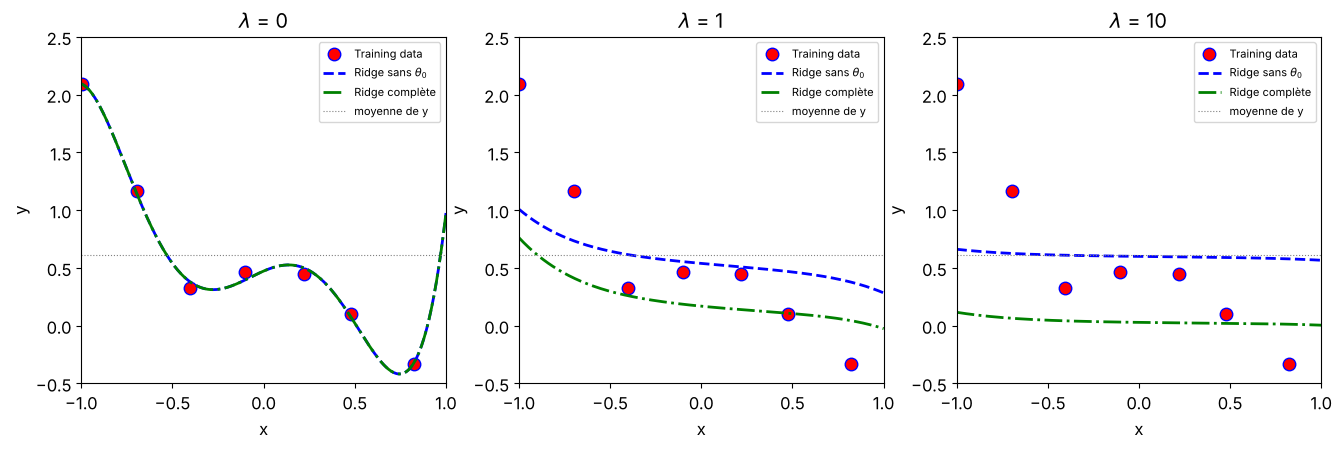

In [6]:
xs = np.linspace(-1, 1, 300)[:, np.newaxis]   # abscisses pour tracer les courbes
print("moyenne de Y : %.4f\n" % y.mean())
print("%6s | %-34s | %-34s" % ("lambda", "Ridge sans theta_0 (TP)", "Ridge complète (avec theta_0)"))
print("%6s | %10s %11s %11s | %10s %11s %11s" % ("", "theta_0", "moy h(X)", "moy h-Y", "theta_0", "moy h(X)", "moy h-Y"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, lam in zip(axes, [0, 1, 10]):
    th_tp, _, _ = descente_gradient(X, y, lam)
    th_rc, _, _ = descente_gradient(X, y, lam, ridge_complet=True)
    h_tp, h_rc = X @ th_tp, X @ th_rc
    print("%6g | %10.4f %11.4f %11.2e | %10.4f %11.4f %11.2e" % (
        lam, th_tp[0, 0], h_tp.mean(), (h_tp - y).mean(), th_rc[0, 0], h_rc.mean(), (h_rc - y).mean()))
    trace_donnees(ax)
    ax.plot(xs, predire(th_tp, xs), "b--", lw=2, label="Ridge sans $\\theta_0$")
    ax.plot(xs, predire(th_rc, xs), "g-.", lw=2, label="Ridge complète")
    ax.axhline(y.mean(), color="gray", lw=0.8, ls=":", label="moyenne de y")
    ax.set_title("$\\lambda$ = %g" % lam)
    ax.legend(fontsize=8)
plt.show()

In [7]:
# invariance par translation des cibles : on décale Y de c = 10
c, lam = 10, 1
for complet in (False, True):
    th1 = equation_normale(X, y, lam, complet)
    th2 = equation_normale(X, y + c, lam, complet)
    print("Ridge complète" if complet else "Ridge sans theta_0",
          ": h(X; Y+c) - h(X; Y) =", (X @ th2 - X @ th1).ravel())

Ridge sans theta_0 : h(X; Y+c) - h(X; Y) = [10. 10. 10. 10. 10. 10. 10.]
Ridge complète : h(X; Y+c) - h(X; Y) = [5.4094 4.008  3.3979 3.1555 3.1411 3.2947 3.8109]


**Analyse.**

1. **Sans pénalisation de $\theta_0$**, la composante $k=0$ du gradient ne contient pas de terme de régularisation. À l'optimum on a donc $\frac{1}{m}\sum_i (h_\theta(x_i) - y_i) = 0$ : **la moyenne des prédictions est toujours égale à la moyenne des données**, quel que soit $\lambda$ (colonne « moy h-Y » nulle à la précision machine). Quand $\lambda$ augmente, la courbe est aplatie vers la **droite horizontale $y = \overline{Y}$**, qui est la meilleure hypothèse constante : c'est le comportement attendu d'un modèle « simple ».
2. **Avec la régularisation de Ridge complète**, $\theta_0$ est lui aussi rétréci vers 0. Quand $\lambda$ augmente, toute la courbe est tirée vers l'axe $y = 0$ : pour $\lambda = 10$ le modèle sous-estime systématiquement toutes les données (moyenne des erreurs $\approx -0.57$). On introduit ainsi un **biais systématique** qui n'a rien à voir avec la complexité du modèle.
3. $\theta_0$ ne règle que le **niveau** (la translation verticale) de la courbe ; il ne participe pas aux oscillations responsables du sur-apprentissage. Le pénaliser n'apporte donc aucun gain contre l'over-fitting. Pire, le résultat dépend alors de l'origine choisie pour $y$ : si l'on ajoute une constante $c$ aux données, le modèle « sans $\theta_0$ » est simplement translaté de $c$, alors que le modèle « Ridge complète » ne l'est pas (dernière cellule).

**Conclusion :** la variante proposée dans le TP (ne pas pénaliser $\theta_0$) est la bonne. C'est d'ailleurs le choix fait par `scikit-learn`, dont la classe `Ridge` ne pénalise jamais l'ordonnée à l'origine (`intercept_`).

## Mise en oeuvre

Il s’agit d’adapter l’algorithme de régression linéaire écrite sous forme matricielle et modifié à partir des formules précédents pour intégrer le terme de régularisation. 

Comme cela est expliqué dans le cours, on va ramener le problème de regression polynomiale univarié à un problème de régression linéaire multivarié, en constituant une matrice X de la façon suivante à partir du vecteur colonne x de la donnée initiale :


`X=np.block([[xone,x,x**2,x**3,x**4,x**5]])`

Réaliser cette régression pour $\lambda = 0, \lambda = 1, \lambda = 10$, puis tracer la courbe résultante sur le même graphique que les données. On doit alors obtenir une figure comparable à la suivante :

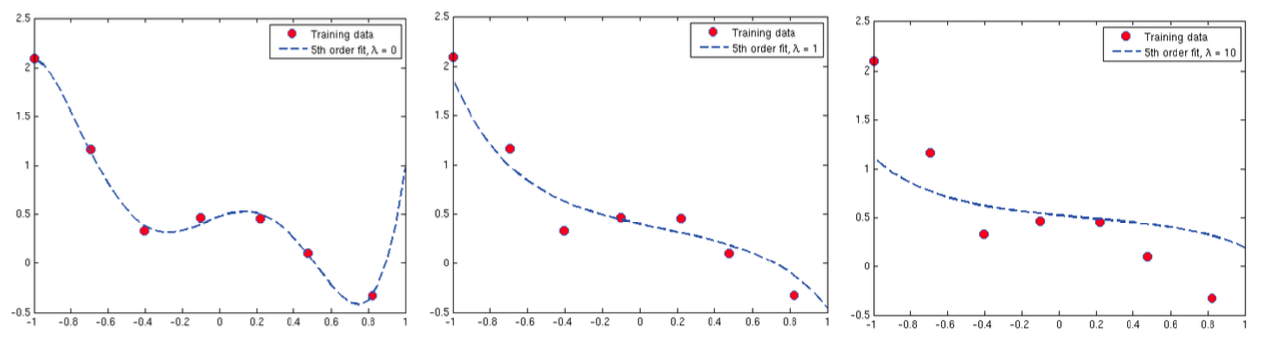


### Réponse : Régression régularisée pour $\lambda = 0, 1, 10$

lambda = 0   :  99585 itérations, J = 0.000754, écart avec l'équation normale = 2.8e-07
             theta = [ 0.4725  0.6814 -1.3801 -5.9777  2.4417  4.7371]
lambda = 1   :     76 itérations, J = 0.199776, écart avec l'équation normale = 7.6e-11
             theta = [ 0.5388 -0.1447  0.0482 -0.1168  0.0589 -0.1009]
lambda = 10  :    477 itérations, J = 0.259752, écart avec l'équation normale = 9.3e-11
             theta = [ 0.5994 -0.0192  0.0064 -0.0153  0.0078 -0.0132]


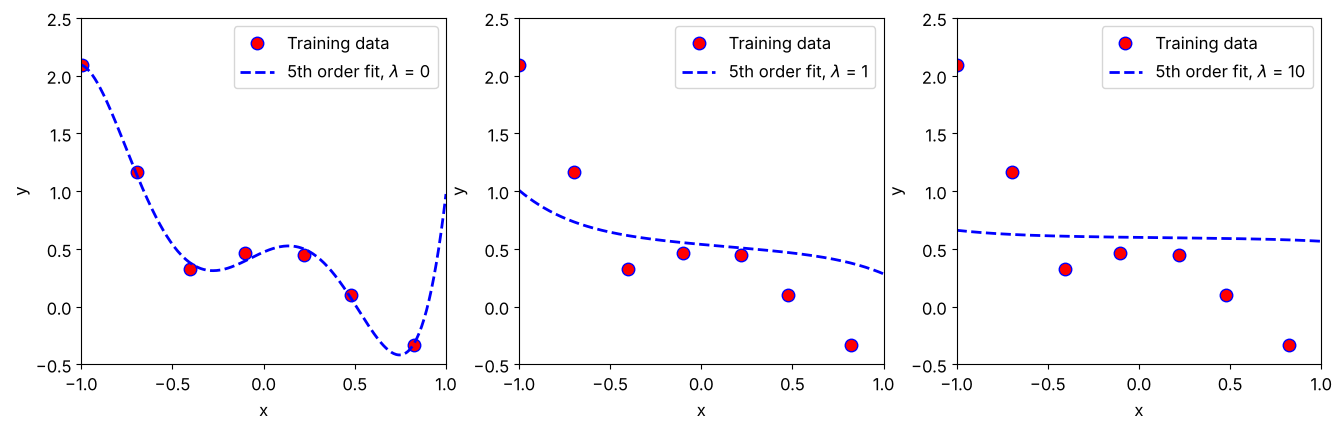

In [8]:
lambdas = [0, 1, 10]
resultats = {}
for lam in lambdas:
    theta, J_hist, n_it = descente_gradient(X, y, lam)
    resultats[lam] = (theta, J_hist)
    print("lambda = %-3g : %6d itérations, J = %.6f, écart avec l'équation normale = %.1e"
          % (lam, n_it, J_hist[-1], np.abs(theta - equation_normale(X, y, lam)).max()))
    print("             theta =", theta.ravel())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, lam in zip(axes, lambdas):
    trace_donnees(ax)
    ax.plot(xs, predire(resultats[lam][0], xs), "b--", lw=2,
            label="5th order fit, $\\lambda$ = %g" % lam)
    ax.legend(loc="upper right")
plt.show()

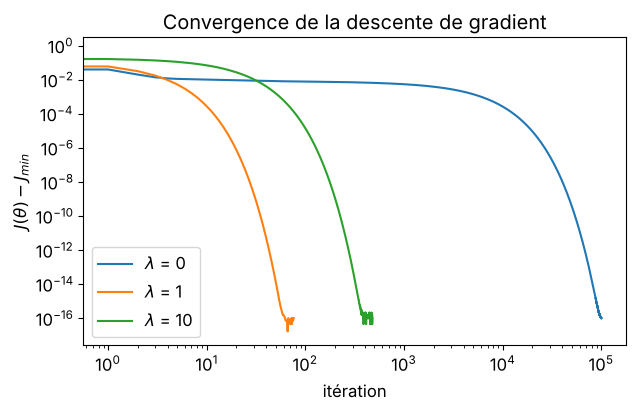

In [9]:
# convergence de la méthode de gradient
plt.figure(figsize=(7, 4))
for lam in lambdas:
    J_hist = resultats[lam][1]
    plt.semilogy(J_hist - J_hist[-1] + 1e-16, label="$\\lambda$ = %g" % lam)
plt.xscale("log")
plt.xlabel("itération")
plt.ylabel("$J(\\theta) - J_{min}$")
plt.title("Convergence de la descente de gradient")
plt.legend()
plt.show()

**Analyse.**

- **$\lambda = 0$ (pas de régularisation)** : la courbe passe quasiment par tous les points ($J \approx 7.5\cdot10^{-4}$) mais oscille fortement entre eux et plonge brutalement après le dernier point ($x > 0.8$). Les coefficients sont grands ($|\theta_3| \approx 6$). C'est un cas typique de **sur-apprentissage** : le modèle apprend le bruit des données et serait peu fiable sur de nouveaux points.
- **$\lambda = 1$ et $\lambda = 10$** : les coefficients $\theta_1,\dots,\theta_5$ deviennent très petits et la courbe est lissée ; pour $\lambda = 10$ elle est presque une droite horizontale au niveau de la moyenne des $y$ : on est en **sous-apprentissage** (le modèle ne suit plus la tendance décroissante des données).
- La descente de gradient converge vers la solution exacte (écart avec l'équation normale de l'ordre de $10^{-10}$ pour $\lambda = 1$ et $10$, et $3\cdot10^{-7}$ pour $\lambda = 0$, où le mauvais conditionnement rend la convergence plus lente). Le cas $\lambda = 0$ demande beaucoup plus d'itérations car le problème est mal conditionné ; la régularisation améliore aussi le conditionnement, et donc la vitesse de convergence.

**Remarque sur l'échelle de $\lambda$.** Nos courbes pour $\lambda = 1$ et $\lambda = 10$ sont nettement plus lissées que celles de la figure de l'énoncé. Ce n'est pas une erreur : la figure de l'énoncé a été obtenue avec la convention (classique, par exemple dans le cours d'Andrew Ng) où le terme de régularisation est **divisé par $2m$** :

$$
J'(\theta) = \frac{1}{2m}\sum_{i=1}^{m}\left(h_\theta(x_i)-y_i\right)^2+\frac{\lambda'}{2m} \sum_{j=1}^{n}\theta_j^2 .
$$

Les deux fonctions de coût ont le même minimum dès que $\lambda = \lambda'/(2m) = \lambda'/14$. Pour le vérifier, on relance nos fonctions (inchangées) avec $\lambda = \lambda'/(2m)$ pour $\lambda' = 0, 1, 10$ : on retrouve exactement la figure de l'énoncé.

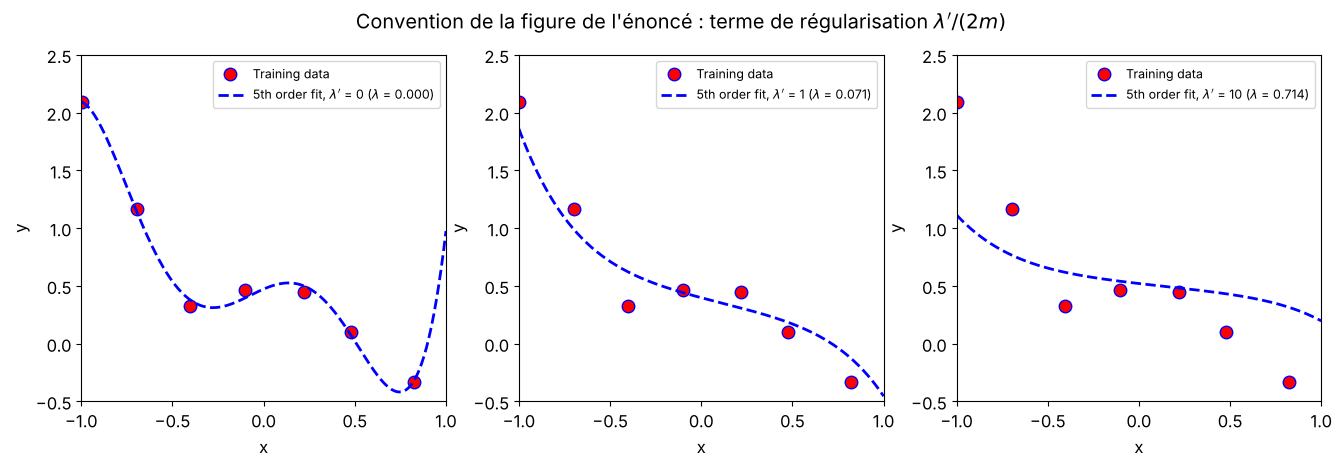

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, lam_p in zip(axes, [0, 1, 10]):
    theta, _, _ = descente_gradient(X, y, lam_p / (2 * m))
    trace_donnees(ax)
    ax.plot(xs, predire(theta, xs), "b--", lw=2,
            label="5th order fit, $\\lambda'$ = %g ($\\lambda$ = %.3f)" % (lam_p, lam_p / (2 * m)))
    ax.legend(loc="upper right", fontsize=9)
plt.suptitle("Convention de la figure de l'énoncé : terme de régularisation $\\lambda'/(2m)$")
plt.show()

Avec cette convention, $\lambda' = 1$ donne un bon ajustement qui suit la tendance des données sans osciller, et $\lambda' = 10$ commence à sous-apprendre (la courbe ne remonte plus jusqu'au premier point). Dans toute la suite, **on garde la fonction de coût de l'énoncé** ($\lambda$ non divisé par $2m$) et on indique, quand c'est utile, la valeur équivalente $\lambda' = 2m\lambda = 14\lambda$.

## Compromis biais-variance

Calculer une valeur de $\lambda$ qui réalise le bon compromis entre biais du modèle et variance du modèle. On pourra faire les mêmes calculs que précédemment avec chaque valeur $\lambda$  du vecteur de valeurs $\lambda  = [0,0.5,1,...,5]$ et obtenir une série de courbes comme décrites ci-dessous :

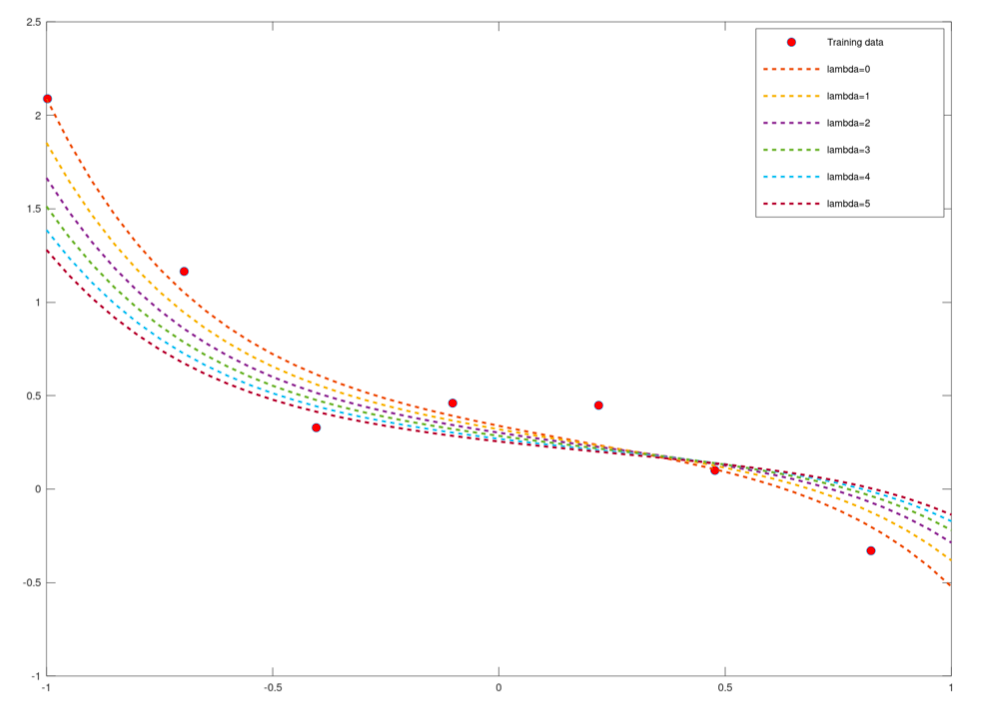

Tracer les courbes de calcul du biais et de la variance du modèle pour chacune de ces valeurs et analyser le résultat pour conclure.

Rappel de la formule de décomposition de l’erreur décrite dans le cours :


- le biais se calcule par 

$$
B(h(X))= E_S[(h-f)(X)]
$$ 

- la variance se calcule par 

$$
Var(h(X))=E_S[h^2(X)]-(E_S[h(X)])^2
$$

On définit ensuite l'*erreur de prédiction attendue* par

$$
Err(h(X)) = B^2(h(X)) + Var(h(X)) + \sigma^2
$$

où $E_S$ correspond ici à l’espérance mathématique à partir d'un échantillonnage $S$.

L’intersection des courbes pour ces deux grandeurs en fonction de $\lambda$ ainsi que l’erreur globale indiquera la valeur du compromis biais-variance.

**Remarque** : Comme précisé dans le cours, l’analyse biais-variance se fait à partir d'un échantillonage sur les données $X$ à partir desquels on obtient autant de fonctions hypothèses sur lesquels on doit moyenner les résultats. Le cas présenté est donc trop réduit pour cette analyse et on ne fait pas d'échantillonnage. Nous allons donc donner des calculs très simplifiés du biais et de la variance dans la section suivante.
Le résultat obtenu est de ce fait peu précis, mais permet quand même de fournir un degré de polynôme pertinent pour la régularisation.

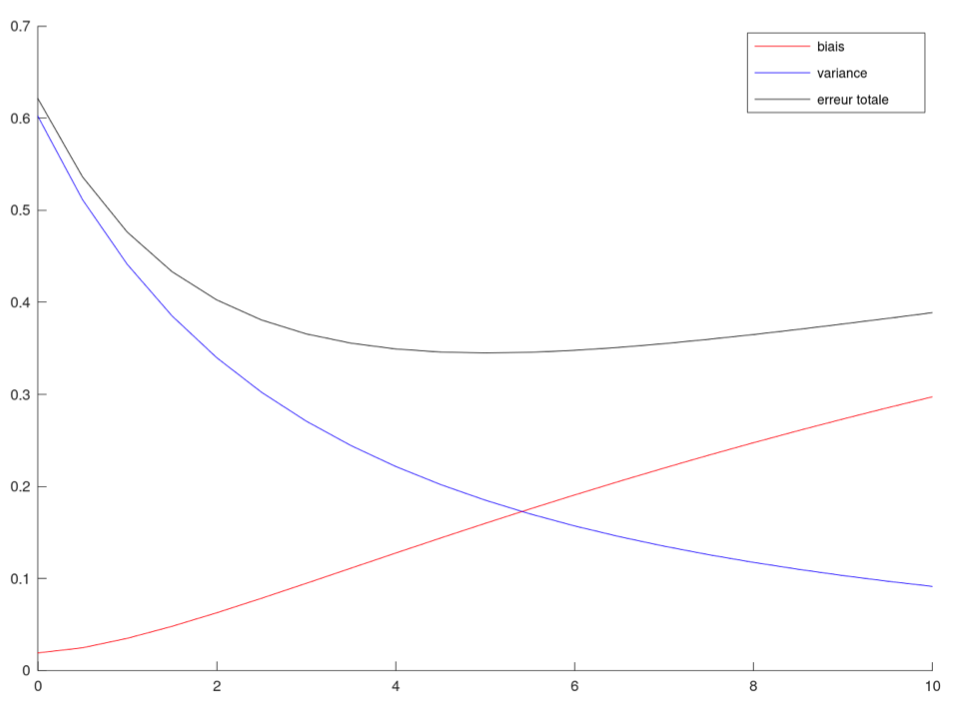

### Réponse : Série de courbes pour $\lambda = 0, 0.5, 1, \dots, 5$

On effectue la régression pour chaque valeur du vecteur $\lambda = [0, 0.5, 1, \dots, 5]$, avec la fonction de coût de l'énoncé (à gauche), puis dans la convention $\lambda'$ de la figure de l'énoncé (à droite). Les courbes de biais et de variance sont calculées dans la section suivante, avec les éléments de calcul proposés.

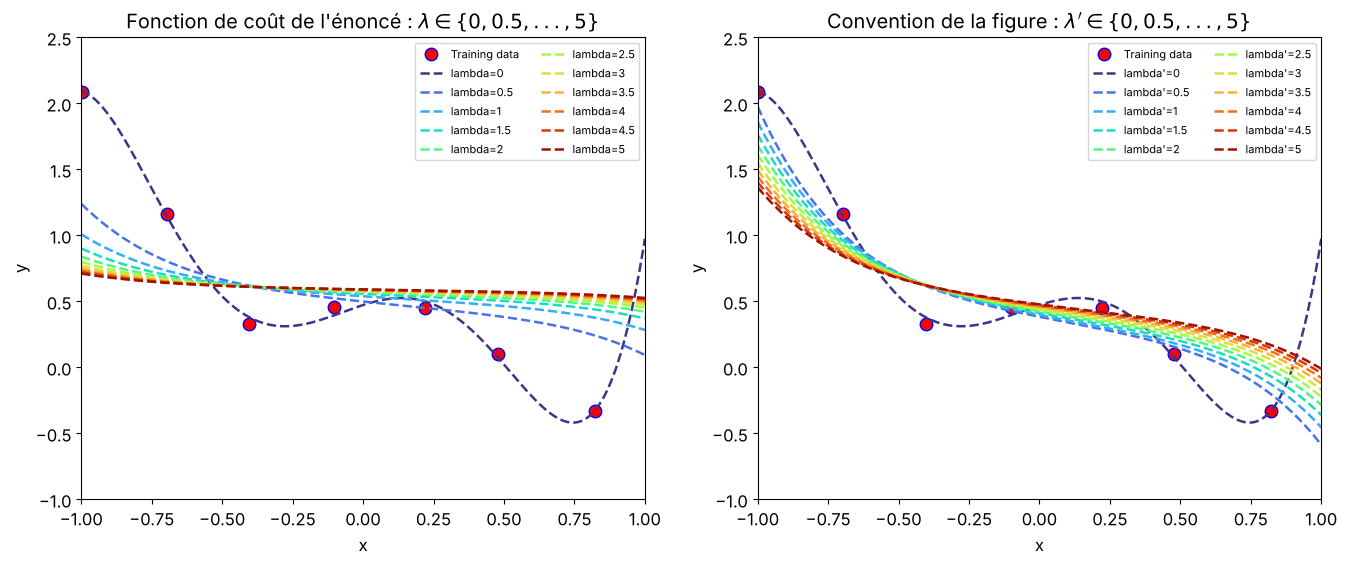

In [11]:
lambdas_serie = np.arange(0, 5.5, 0.5)
couleurs = plt.cm.turbo(np.linspace(0.05, 0.95, len(lambdas_serie)))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, convention in zip(axes, ["enonce", "prime"]):
    trace_donnees(ax)
    for lam, col in zip(lambdas_serie, couleurs):
        lam_calc = lam if convention == "enonce" else lam / (2 * m)
        theta, _, _ = descente_gradient(X, y, lam_calc)
        nom = "lambda" if convention == "enonce" else "lambda'"
        ax.plot(xs, predire(theta, xs), "--", color=col, lw=1.8, label="%s=%g" % (nom, lam))
    ax.set_ylim(-1, 2.5)
    ax.legend(fontsize=8, ncol=2)
axes[0].set_title("Fonction de coût de l'énoncé : $\\lambda \\in \\{0, 0.5, ..., 5\\}$")
axes[1].set_title("Convention de la figure : $\\lambda' \\in \\{0, 0.5, ..., 5\\}$")
plt.show()

Quand $\lambda$ augmente, les courbes sont de plus en plus lissées et tendent vers la droite horizontale $y = \overline{Y}$ : la complexité effective du modèle diminue. Avec la fonction de coût de l'énoncé, l'essentiel de l'évolution a lieu entre $\lambda = 0$ et $\lambda = 0.5$ ; au-delà les courbes sont déjà presque plates. Dans la convention $\lambda'$ (à droite), on retrouve le faisceau de courbes de la figure de l'énoncé.

## Éléments de calcul du compromis biais-variance proposé

Soit $X$ le vecteur ou la matrice des données d’entrée et $Y$ le vecteur des données cible. Nous n’effec-
tuons pas d’échantillonnage, ce qui revient à prendre un seul échantillon contenant toutes les données.
Les calculs d’espérance se simplifient alors en de simples calculs de moyennes.

Le Biais défini par la formule

$$
B(h(X))= E_S[(h-f)(X)]
$$

se simplifie en faisant la moyenne des coefficients du vecteur $h(X)-Y$. 
En effet, ne connaissant pas la fonction $f(x)$, on la remplace par les valeurs du vecteur des données cibles $Y$
Ce calcul s'obtient alors simplement en appelant la fonction `mean`de `numpy`, à laquelle on passera en paramètre le vecteur $h(X)-Y$.

Le calcul de la variance défini par la formule 
$$
Var[h(X)] = E_S[(h(X))^2] - (E_S[h(X)])^2
$$

se simplifie également de manière importante et il est remplacé par un simple appel à la fonction `var`
de `numpy`, à laquelle on passera en paramètre le vecteur $h(X)$.

Comme cela est mentionné, ce calcul de variance est une "interprétation" simplifiée de la définition du cours qui nécessite de mesurer la dispersion des valeurs de $h(x)$ par rapport à un ensemble d'échantillonages que l'on ne fait pas ici dans le TP. Ce calcul de substitution est simple mais produit quand même des résultats exploitables et semblables au comportement attendue de la vraie formule de variance pour les données fournies.

Les courbes du biais et de la variance sont tracées dans cet exercice en prenant en abscisses les valeurs de 
$\lambda$. La *complexité* du modèle est plus grande lorsque $\lambda$ est petit et elle diminue lorsque $\lambda$ grandit ;
en effet, une grande valeur de $\lambda$ va lisser fortement la courbe de régression et absorber les oscillations
qu’elle pourrait produire en minimisant la fonction coût.

Les sens de variation des courbes seront à l’inverse de la figure donnée en cours. Ici la courbe du biais va
croitre alors que celle de la variance va décroitre.

### Réponse : Calcul du biais, de la variance et de l'erreur

**1) Application directe des formules simplifiées.** On applique d'abord exactement ce qui est proposé : biais $=$ `np.mean(h(X) - Y)`, variance $=$ `np.var(h(X))`.

In [12]:
def biais_variance(X, Y, lam):
    """Biais et variance simplifiés (un seul échantillon S = toutes les données)."""
    theta, _, _ = descente_gradient(X, Y, lam)
    h = X @ theta
    biais = np.mean(h - Y)         # E_S[(h - f)(X)] avec f remplacée par Y
    variance = np.var(h)           # E_S[h^2(X)] - (E_S[h(X)])^2
    mse = np.mean((h - Y) ** 2)    # E_S[(h - f)^2(X)], utilisé plus bas
    return biais, variance, mse

lambdas_bv = np.arange(0, 10.5, 0.5)
BV = np.array([biais_variance(X, y, lam) for lam in lambdas_bv])
print("%6s %12s %10s %10s" % ("lambda", "biais", "variance", "mse"))
for lam, (b, v, e) in zip(lambdas_bv, BV):
    print("%6.1f %12.1e %10.4f %10.4f" % (lam, b, v, e))

lambda        biais   variance        mse
   0.0     -1.5e-12     0.5362     0.0015
   0.5     -5.0e-11     0.0921     0.1940
   1.0     -6.6e-11     0.0370     0.2984
   1.5     -6.3e-11     0.0199     0.3553
   2.0     -7.7e-11     0.0124     0.3905
   2.5     -8.0e-11     0.0084     0.4144
   3.0     -8.5e-11     0.0061     0.4317
   3.5     -8.0e-11     0.0046     0.4447
   4.0     -8.5e-11     0.0036     0.4549
   4.5     -9.0e-11     0.0029     0.4631
   5.0     -8.6e-11     0.0024     0.4698
   5.5     -9.0e-11     0.0020     0.4754
   6.0     -8.8e-11     0.0017     0.4801
   6.5     -9.1e-11     0.0015     0.4842
   7.0     -8.9e-11     0.0013     0.4877
   7.5     -9.2e-11     0.0011     0.4908
   8.0     -9.0e-11     0.0010     0.4936
   8.5     -9.3e-11     0.0009     0.4960
   9.0     -9.1e-11     0.0008     0.4982
   9.5     -9.4e-11     0.0007     0.5002
  10.0     -9.2e-11     0.0006     0.5019


**Constat :** avec la régularisation proposée (sans $\theta_0$), le biais `np.mean(h(X) - Y)` est **nul** (inférieur à $10^{-10}$, c'est-à-dire nul aux erreurs d'arrondi près) pour toutes les valeurs de $\lambda$. Ce n'est pas un hasard : on a montré dans la discussion précédente que, $\theta_0$ n'étant pas pénalisé, l'optimum vérifie toujours $\frac{1}{m}\sum_i (h_\theta(x_i)-y_i) = 0$. Les erreurs positives et négatives se compensent exactement, donc cette moyenne **signée** ne peut pas mesurer l'écart entre le modèle et les données : c'est précisément le problème signalé dans le correctif apporté par l'enseignant aux consignes de l'énoncé.

**2) Calcul corrigé du biais (correctif de l'enseignant).** Pour éviter les compensations, on s'inspire du calcul de la fonction de coût et on applique `mean` au vecteur $(h(X)-Y)^2$ (coefficients de $h(X)-Y$ élevés au carré). On obtient directement $B^2$ (ou une bonne approximation), ce qui est cohérent avec le cours (« les valeurs de `rmse` ou de `r2` permettent de mesurer le biais ») :

$$
B^2(h(X)) \;\approx\; E_S\left[(h-f)^2(X)\right] \;\approx\; \frac{1}{m}\sum_{i=1}^{m}\left(h(x_i) - y_i\right)^2
$$

c'est-à-dire `np.mean((h - Y)**2)` (erreur quadratique moyenne), la variance restant calculée par `np.var(h)`.

L'erreur de prédiction attendue est $Err = B^2 + Var + \sigma^2$. Le bruit $\sigma^2$ est inconnu, mais c'est une constante qui ne dépend pas de $\lambda$ : elle ne change pas la position du minimum. On trace donc, comme demandé dans le correctif, l'**erreur totale** $E = B^2(h(X)) + Var(h(X))$, dont le minimum donne la valeur de $\lambda$ réalisant le bon compromis biais-variance.

intersection biais/variance : lambda = 0.335  (lambda' = 2m.lambda = 4.69)
minimum de l'erreur totale  : lambda = 0.365  (lambda' = 2m.lambda = 5.11), erreur = 0.2799


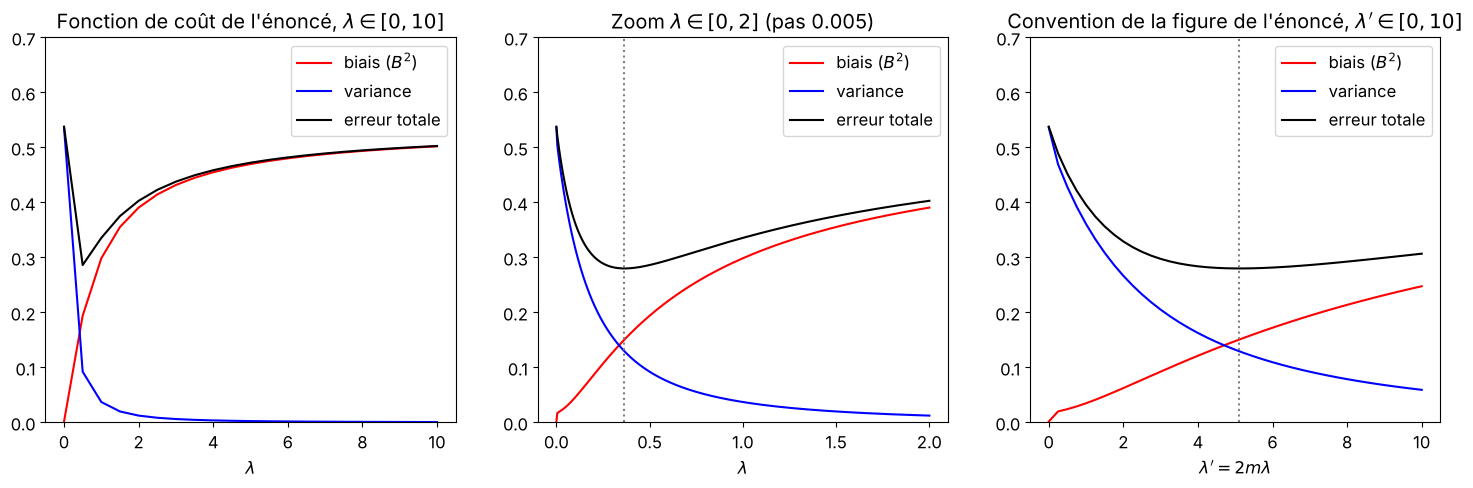

In [13]:
def trace_biais_variance(ax, lams, B2, V, nom="$\\lambda$"):
    ax.plot(lams, B2, "r", label="biais ($B^2$)")
    ax.plot(lams, V, "b", label="variance")
    ax.plot(lams, B2 + V, "k", label="erreur totale")
    ax.set_xlabel(nom)
    ax.legend()

# grille fine pour localiser précisément le compromis (fonction de coût de l'énoncé)
lambdas_fin = np.arange(0, 2.001, 0.005)
BV_fin = np.array([biais_variance(X, y, lam) for lam in lambdas_fin])
B2_fin, V_fin = BV_fin[:, 2], BV_fin[:, 1]
i_c = np.argmin(np.abs(B2_fin - V_fin))     # intersection biais / variance
i_m = np.argmin(B2_fin + V_fin)            # minimum de l'erreur totale
lam_c, lam_m = lambdas_fin[i_c], lambdas_fin[i_m]
print("intersection biais/variance : lambda = %.3f  (lambda' = 2m.lambda = %.2f)" % (lam_c, 2 * m * lam_c))
print("minimum de l'erreur totale  : lambda = %.3f  (lambda' = 2m.lambda = %.2f), erreur = %.4f"
      % (lam_m, 2 * m * lam_m, (B2_fin + V_fin)[i_m]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
trace_biais_variance(axes[0], lambdas_bv, BV[:, 2], BV[:, 1])
axes[0].set_title("Fonction de coût de l'énoncé, $\\lambda \\in [0, 10]$")
trace_biais_variance(axes[1], lambdas_fin, B2_fin, V_fin)
axes[1].axvline(lam_m, color="gray", ls=":")
axes[1].set_title("Zoom $\\lambda \\in [0, 2]$ (pas 0.005)")
lam_p = np.arange(0, 10.25, 0.25)
BV_p = np.array([biais_variance(X, y, l / (2 * m)) for l in lam_p])
trace_biais_variance(axes[2], lam_p, BV_p[:, 2], BV_p[:, 1], nom="$\\lambda' = 2m\\lambda$")
axes[2].axvline(2 * m * lam_m, color="gray", ls=":")
axes[2].set_title("Convention de la figure de l'énoncé, $\\lambda' \\in [0, 10]$")
for ax in axes:
    ax.set_ylim(0, 0.7)
plt.show()

**Analyse des courbes.**

- Comme annoncé dans l'énoncé, les sens de variation sont inversés par rapport à la figure du cours (où l'abscisse est le degré du polynôme) : ici la complexité diminue quand $\lambda$ augmente. **Le biais croît** avec $\lambda$ (le modèle lissé s'éloigne des données : sous-apprentissage) et **la variance décroît** (le modèle oscille de moins en moins et tend vers une constante).
- Pour $\lambda = 0$, le biais est quasi nul mais la variance est maximale ($\approx 0.54$) : sur-apprentissage. Pour $\lambda$ grand, la variance est presque nulle mais le biais tend vers la variance des données ($\approx 0.54$) : sous-apprentissage.
- L'erreur totale a la forme en « U » attendue. Son minimum et l'intersection des courbes de biais et de variance sont très proches : **$\lambda \approx 0.34$ à $0.37$** avec la fonction de coût de l'énoncé.
- Le graphique de droite, tracé avec la convention $\lambda' = 2m\lambda$, reproduit la figure de l'énoncé : intersection et minimum vers $\lambda' \approx 5$.

On retient donc la valeur de compromis **$\lambda^* \approx 0.36$** (soit $\lambda' \approx 5$ dans la convention de la figure). Comme annoncé par l'enseignant, cette valeur « optimale » est différente de celle que l'on lit sur la figure de l'énoncé ($\lambda \approx 5$) : la différence vient du facteur $2m$ dans le terme de régularisation, et non d'une erreur de calcul.

lambda* = 0.365, theta* = [ 0.4789 -0.2675  0.088  -0.2212  0.1091 -0.1909]
rmse = 0.3881


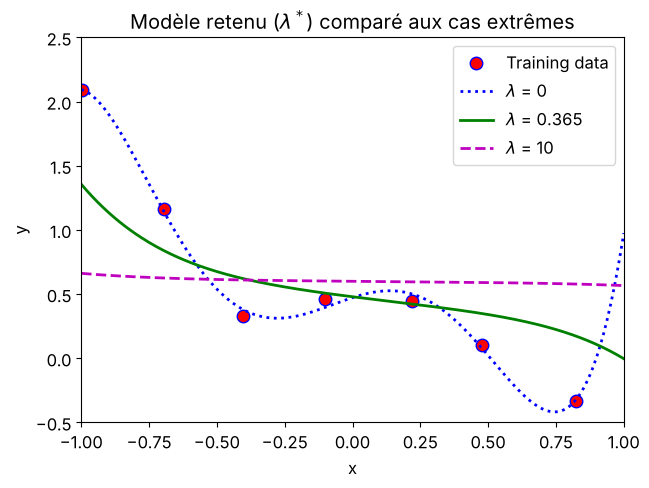

In [14]:
lam_opt = lam_m
theta_opt, _, _ = descente_gradient(X, y, lam_opt)
h_opt = X @ theta_opt
print("lambda* = %.3f, theta* =" % lam_opt, theta_opt.ravel())
print("rmse = %.4f" % np.sqrt(np.mean((h_opt - y) ** 2)))

fig, ax = plt.subplots(figsize=(7, 5))
trace_donnees(ax)
for lam, style in [(0, "b:"), (lam_opt, "g-"), (10, "m--")]:
    th, _, _ = descente_gradient(X, y, lam)
    ax.plot(xs, predire(th, xs), style, lw=2, label="$\\lambda$ = %.3g" % lam)
ax.set_title("Modèle retenu ($\\lambda^*$) comparé aux cas extrêmes")
ax.legend()
plt.show()

Avec $\lambda^*$, la courbe suit la tendance décroissante des données sans osciller entre les points : elle se situe entre le modèle sur-appris ($\lambda = 0$) et le modèle sous-appris ($\lambda = 10$).

*Limite de la méthode.* Comme le souligne l'énoncé, cette analyse est très simplifiée : sans échantillonnage, `np.var(h)` mesure la dispersion des valeurs de $h$ autour de leur moyenne, et non leur dispersion d'un échantillon à l'autre. Elle pénalise donc aussi la variation « utile » de la courbe (la décroissance des données), ce qui tend à surestimer la régularisation nécessaire. La valeur obtenue reste néanmoins une indication raisonnable de l'ordre de grandeur de $\lambda$.

## Reprise du développement en utilisant la bibliothèque `scikit-learn`
Reprendre le programme en Python en remplaçant les fonctions de calcul de régression par les fonctions prédéfinies de la bibliothèse `scikit-learn` qui implémente les techniques de régularisation connues dont celle de Ridge sur laquelle s'appuie la méthode proposée dans le TP.

### Réponse : Reprise avec `scikit-learn`

Comme dans le cours, on utilise `PolynomialFeatures` pour construire les descripteurs $x, x^2, \dots, x^5$, puis on remplace notre descente de gradient par les classes de `sklearn.linear_model` :

- $\lambda = 0$ : `LinearRegression` ;
- $\lambda > 0$ : `Ridge`, qui minimise $\|Y - X\theta\|^2 + \alpha\,\|\theta_-\|^2$, **sans pénaliser l'ordonnée à l'origine** (`intercept_`), exactement comme dans le TP. En multipliant notre $J$ par $2m$, on obtient la correspondance $\alpha = 2m\lambda$.

lambda = 0   : theta = [ 0.4725  0.6814 -1.3801 -5.9777  2.4417  4.7371]  | écart avec notre gradient = 2.8e-07
lambda = 1   : theta = [ 0.5388 -0.1447  0.0482 -0.1168  0.0589 -0.1009]  | écart avec notre gradient = 7.6e-11
lambda = 10  : theta = [ 0.5994 -0.0192  0.0064 -0.0153  0.0078 -0.0132]  | écart avec notre gradient = 9.3e-11


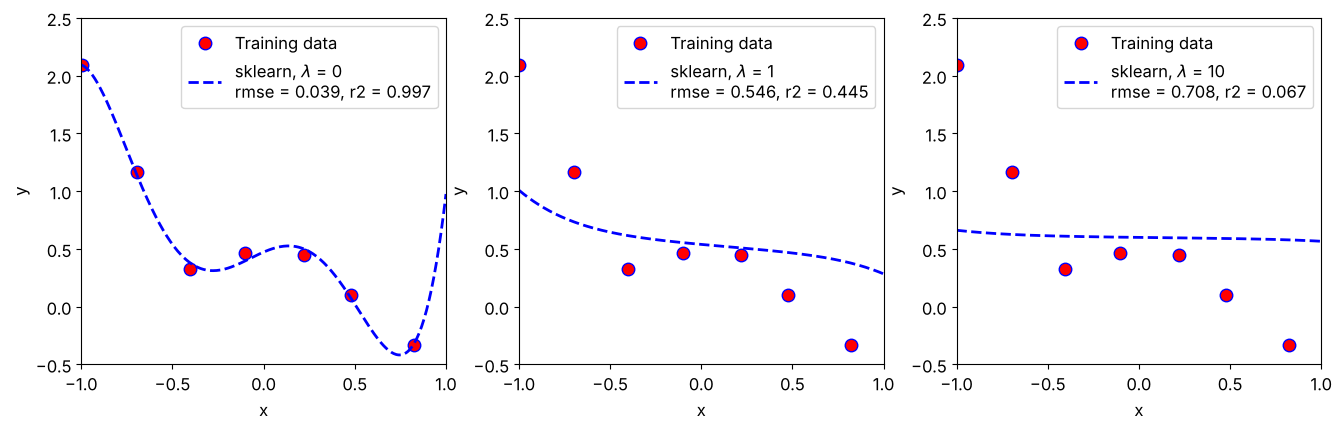

In [15]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import LeaveOneOut, cross_val_score

poly = PolynomialFeatures(degree=5, include_bias=False)   # x, x^2, ..., x^5
x_poly = poly.fit_transform(x)
xs_poly = poly.transform(xs)


def modele_sklearn(lam):
    """Régression polynomiale régularisée équivalente à la fonction de coût du TP."""
    if lam == 0:
        return LinearRegression()
    return Ridge(alpha=2 * m * lam)


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, lam in zip(axes, [0, 1, 10]):
    model = modele_sklearn(lam)
    model.fit(x_poly, y)
    y_pred = model.predict(x_poly)
    theta_sk = np.concatenate([np.ravel(model.intercept_), np.ravel(model.coef_)])
    ecart = np.abs(theta_sk - resultats[lam][0].ravel()).max()
    rmse = np.sqrt(mean_squared_error(y, y_pred))
    r2 = r2_score(y, y_pred)
    print("lambda = %-3g : theta =" % lam, theta_sk, " | écart avec notre gradient = %.1e" % ecart)
    trace_donnees(ax)
    ax.plot(xs, model.predict(xs_poly), "b--", lw=2,
            label="sklearn, $\\lambda$ = %g\nrmse = %.3f, r2 = %.3f" % (lam, rmse, r2))
    ax.legend(loc="upper right")
plt.show()

Les coefficients obtenus avec `scikit-learn` sont identiques à ceux de notre implémentation par descente de gradient (écart d'au plus $3\cdot10^{-7}$, dû au critère d'arrêt de la descente de gradient), et les figures sont les mêmes. Les indicateurs `rmse` et `r2` vus en cours confirment l'analyse : `r2` $\approx 1$ pour $\lambda = 0$ (le modèle colle aux données, sur-apprentissage) et `r2` proche de 0 pour $\lambda = 10$ (le modèle n'explique presque plus rien, sous-apprentissage).

**Compromis biais-variance avec `scikit-learn`.** On refait le même calcul avec `Ridge`, en mesurant le biais par `mean_squared_error`.

écart max avec notre implémentation : biais 3.5e-11, variance 1.6e-09
minimum de l'erreur totale avec sklearn : lambda = 0.365 (alpha sklearn = 5.11)


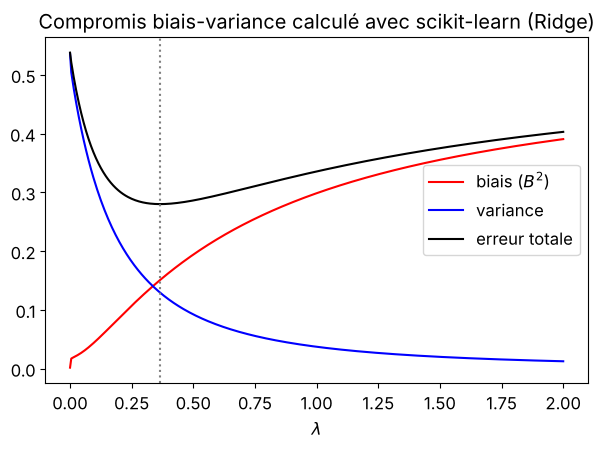

In [16]:
B2_sk, V_sk = [], []
for lam in lambdas_fin:
    model = modele_sklearn(lam).fit(x_poly, y)
    h = model.predict(x_poly)
    B2_sk.append(mean_squared_error(y, h))
    V_sk.append(np.var(h))
B2_sk, V_sk = np.array(B2_sk), np.array(V_sk)
lam_m_sk = lambdas_fin[np.argmin(B2_sk + V_sk)]
print("écart max avec notre implémentation : biais %.1e, variance %.1e"
      % (np.abs(B2_sk - B2_fin).max(), np.abs(V_sk - V_fin).max()))
print("minimum de l'erreur totale avec sklearn : lambda = %.3f (alpha sklearn = %.2f)" % (lam_m_sk, 2 * m * lam_m_sk))

fig, ax = plt.subplots(figsize=(7, 4.5))
trace_biais_variance(ax, lambdas_fin, B2_sk, V_sk)
ax.axvline(lam_m_sk, color="gray", ls=":")
ax.set_title("Compromis biais-variance calculé avec scikit-learn (Ridge)")
plt.show()

On retrouve exactement les mêmes courbes et la même valeur $\lambda^* \approx 0.36$ (soit `alpha` $\approx 5$ dans `Ridge`).

**Pour aller plus loin : autres régularisations et validation croisée.** `scikit-learn` fournit aussi les régularisations Lasso (norme $L_1$) et ElasticNet présentées dans le cours. On compare rapidement Ridge et Lasso, puis on estime l'erreur de généralisation par validation croisée *leave-one-out* (`LeaveOneOut` : on apprend sur 6 points et on teste sur le 7e, pour chacun des 7 points).

coefficients Ridge (alpha = 5.11) : [-0.2675  0.088  -0.2212  0.1091 -0.1909]
coefficients Lasso (alpha = 0.01)  : [-0.1433  0.008  -1.3214  0.1856 -0.    ]


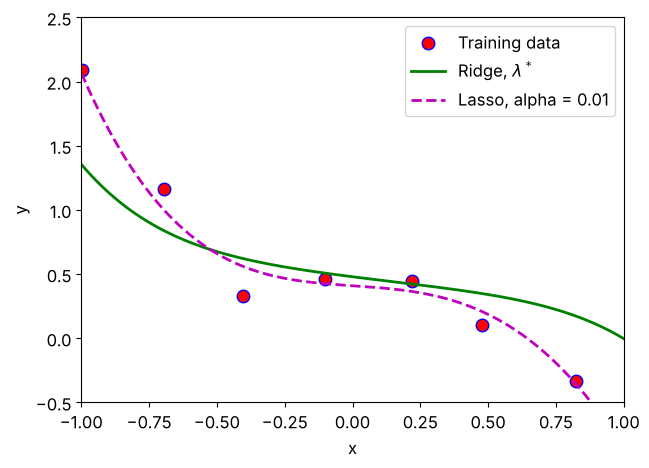


Erreur leave-one-out (moyenne des erreurs quadratiques sur le point exclu) :
  lambda =  0.000 : 3.4995
  lambda =  0.010 : 0.0688
  lambda =  0.050 : 0.1656
  lambda =  0.365 : 0.4257
  lambda =  1.000 : 0.5690
  lambda = 10.000 : 0.7104


In [17]:
ridge = Ridge(alpha=2 * m * lam_opt).fit(x_poly, y)
lasso = Lasso(alpha=0.01, max_iter=100000).fit(x_poly, y.ravel())
print("coefficients Ridge (alpha = %.2f) :" % (2 * m * lam_opt), ridge.coef_.ravel())
print("coefficients Lasso (alpha = 0.01)  :", lasso.coef_)

fig, ax = plt.subplots(figsize=(7, 5))
trace_donnees(ax)
ax.plot(xs, ridge.predict(xs_poly), "g-", lw=2, label="Ridge, $\\lambda^*$")
ax.plot(xs, lasso.predict(xs_poly), "m--", lw=2, label="Lasso, alpha = 0.01")
ax.legend()
plt.show()

print("\nErreur leave-one-out (moyenne des erreurs quadratiques sur le point exclu) :")
for lam in [0, 0.01, 0.05, lam_opt, 1, 10]:
    scores = cross_val_score(modele_sklearn(lam), x_poly, y.ravel(), cv=LeaveOneOut(),
                             scoring="neg_mean_squared_error")
    print("  lambda = %6.3f : %.4f" % (lam, -scores.mean()))

- Le Lasso peut annuler des coefficients (ici celui de $x^5$ : sélection de descripteurs), alors que Ridge les réduit tous sans les annuler ; les deux courbes ont une allure voisine.
- La validation croisée confirme qu'il faut régulariser : sans régularisation ($\lambda = 0$), l'erreur sur le point exclu est très grande (avec 6 points, le polynôme de degré 5 interpole exactement les données d'apprentissage et oscille fortement), et une régularisation trop forte ($\lambda = 10$) dégrade aussi la prédiction. Le minimum de cette erreur se situe à une régularisation plus faible que celle donnée par l'analyse biais-variance simplifiée, ce qui illustre la limite signalée plus haut. Cette estimation est elle-même très bruitée (chaque modèle n'est appris que sur 6 points) : avec si peu de données, la valeur de $\lambda$ ne peut être déterminée que de façon approximative, et l'analyse biais-variance demandée fournit un ordre de grandeur plutôt prudent (modèle lisse).

## Conclusion

- Le problème de régression polynomiale de degré 5 a été ramené à une régression linéaire multivariée sur la matrice $X = [1, x, \dots, x^5]$, puis résolu par descente de gradient avec la fonction de coût régularisée de l'énoncé (Ridge sans $\theta_0$). Le résultat a été contrôlé par l'équation normale régularisée $(X^tX + 2m\lambda D)\theta = X^tY$.
- Sans régularisation ($\lambda = 0$), le modèle sur-apprend : il passe par les points mais oscille. Une forte régularisation ($\lambda = 10$) aplatit la courbe vers la moyenne des données : sous-apprentissage.
- Ne pas pénaliser $\theta_0$ est essentiel : sinon la courbe est tirée vers $y = 0$ et le modèle devient systématiquement biaisé (et dépend de l'origine choisie pour $y$).
- La formule simplifiée du biais `np.mean(h - Y)` est identiquement nulle avec cette régularisation (les écarts positifs et négatifs se compensent) ; conformément au correctif de l'enseignant, on a donc calculé $B^2$ = `np.mean((h - Y)**2)` et l'erreur $E = B^2 + Var$. L'analyse biais-variance donne alors un compromis pour **$\lambda^* \approx 0.36$** avec la fonction de coût de l'énoncé, soit $\lambda' \approx 5$ dans la convention $\lambda'/(2m)$ utilisée pour les figures de l'énoncé (et `alpha` $\approx 5$ dans `Ridge` de `scikit-learn`).
- `scikit-learn` (`PolynomialFeatures` + `Ridge` avec `alpha` $= 2m\lambda$) donne exactement les mêmes résultats que notre implémentation.